# Supplementary Figure 3 — `neymotin_2020_model` comparison

Connectivity space constant, rheobase, and single-cell dipoles for the original
`neymotin_2020_model`, for comparison with `duecker_ET_model`. Figures are written
to `results/network_sim/suppfig3/`.

| Manuscript figure | Section |
| --- | --- |
| Supp. Fig. 3a,b | Neymotin connectivity matrices + space constant |
| Supp. Fig. 3c | Rheobase (neymotin vs duecker) + neymotin single-cell dipoles |

In [1]:
import os

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import Normalize
from matplotlib.gridspec import GridSpec

from neuron import h

from hnn_core import duecker_ET_model, neymotin_2020_model, simulate_dipole
from hnn_tuning.plot_utils import add_scalebar
from hnn_tuning import results_dir
from hnn_tuning.pyramidal_sim_utils import stim_dpl, plot_dpl

mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
plt.rcParams['font.size'] = 6
figpth = results_dir('network_sim', 'suppfig3')
os.makedirs(figpth, exist_ok=True)


def conn_space_constant(x, lamtha):
    """Connection-weight profile for a given space constant (Campagnola 2022 ref)."""
    inplane_distance = 1
    A = 0.1
    return A * np.exp(-(x / (lamtha * inplane_distance)) ** 2)


def find_basal_rheo(model='neymotin'):
    """Rheobase (nA) per cell type, by sweeping a tonic bias until the cell spikes."""
    ampl = np.linspace(0.01, 1., 80)
    rheo = np.zeros((4,))

    for a in ampl:
        if model == 'neymotin':
            net = neymotin_2020_model(mesh_shape=(1, 1))
        else:
            net = duecker_ET_model(mesh_shape=(1, 1))

        net.clear_connectivity()

        if model == 'neymotin':
            net.add_tonic_bias(cell_type='L2_basket', amplitude=a, t0=10., tstop=100.)
            net.add_tonic_bias(cell_type='L5_basket', amplitude=a, t0=10., tstop=100.)
        elif model == 'duecker':
            net.add_tonic_bias(cell_type='L2_inhibitory', amplitude=a, t0=10., tstop=100.)
            net.add_tonic_bias(cell_type='L5_inhibitory', amplitude=a, t0=10., tstop=100.)
        net.add_tonic_bias(cell_type='L2_pyramidal', amplitude=a, t0=10., tstop=100., section='basal_2', bias_name='bias_1')
        net.add_tonic_bias(cell_type='L2_pyramidal', amplitude=a, t0=10., tstop=100., section='basal_3', bias_name='bias_2')
        net.add_tonic_bias(cell_type='L2_pyramidal', amplitude=a, t0=10., tstop=100., section='apical_oblique', bias_name='bias_3')
        net.add_tonic_bias(cell_type='L5_pyramidal', amplitude=a, t0=10., tstop=100., section='basal_1', bias_name='bias_1')
        net.add_tonic_bias(cell_type='L5_pyramidal', amplitude=a, t0=10., tstop=100., section='basal_2', bias_name='bias_2')
        net.add_tonic_bias(cell_type='L5_pyramidal', amplitude=a, t0=10., tstop=100., section='apical_oblique', bias_name='apical_oblique')

        simulate_dipole(net, tstop=100, n_trials=1, dt=0.01, record_vsec='soma')

        for i in range(4):
            if i == 2:
                rheo[i] = rheo[0]
            if rheo[i] == 0:
                if any((np.array(net.cell_response.spike_gids[0]) == i)):
                    rheo[i] = a
                    break

    return rheo

## Supp. Fig. 3a,b — Neymotin connectivity matrices + space constant

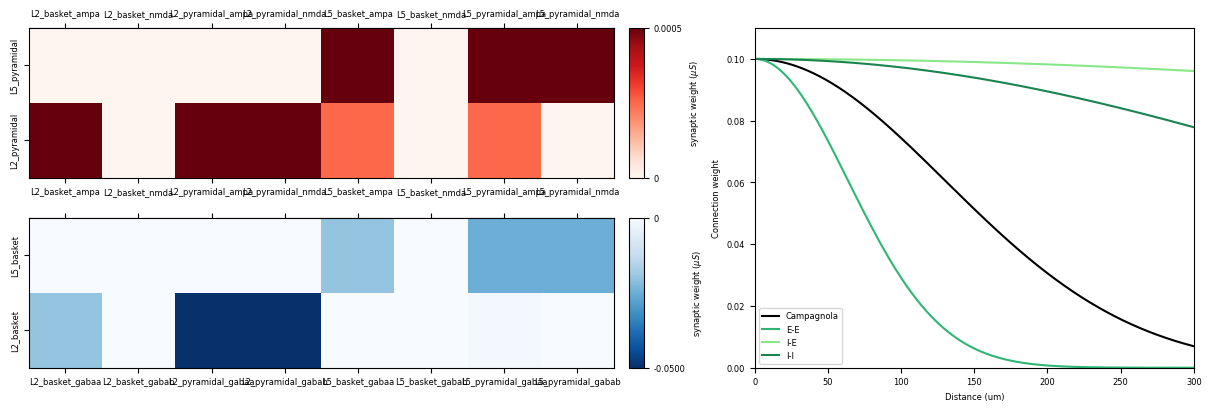

In [2]:
net = neymotin_2020_model()

targets = ['L2_basket', 'L2_pyramidal', 'L5_basket', 'L5_pyramidal']
src_inh = ['L2_basket', 'L5_basket']
src_pyr = ['L2_pyramidal', 'L5_pyramidal']
E_receptors = ['ampa', 'nmda']
I_receptors = ['gabaa', 'gabab']

connectivity_data = dict()
for src in targets:
    connectivity_data[src] = dict()
    for conn in net.connectivity:
        if conn['src_type'] == src:
            t_type = conn['target_type']
            if connectivity_data[src].get(t_type) is None:
                connectivity_data[src][t_type] = dict()
            rec = conn['receptor']
            connectivity_data[src][t_type][rec] = conn['nc_dict']['A_weight']

conn_im_pyr = np.zeros((len(src_pyr), len(targets), 2))
conn_im_inh = np.zeros((len(src_inh), len(targets), 2))

xticklabels_pyr = []
for target in targets:
    for rec in E_receptors:
        xticklabels_pyr.append(f'{target}_{rec}')

for s, src in enumerate(src_pyr):
    for t, target in enumerate(targets):
        if connectivity_data[src].get(target) is not None:
            for i, rec in enumerate(E_receptors):
                if rec in connectivity_data[src][target]:
                    conn_im_pyr[s, t, i] = connectivity_data[src][target][rec]

xticklabels_inh = []
for target in targets:
    for rec in I_receptors:
        xticklabels_inh.append(f'{target}_{rec}')

for s, src in enumerate(src_inh):
    for t, target in enumerate(targets):
        if connectivity_data[src].get(target) is not None:
            for i, rec in enumerate(I_receptors):
                if rec in connectivity_data[src][target]:
                    conn_im_inh[s, t, i] = -connectivity_data[src][target][rec]

fig = plt.figure(figsize=(12, 4.), constrained_layout=True)
gs = GridSpec(2, 3, width_ratios=[1, 0.025, 0.75], figure=fig)
ax = [None] * 3
ax[0] = fig.add_subplot(gs[0, 0])
ax[1] = fig.add_subplot(gs[1, 0])
cax1 = fig.add_subplot(gs[0, 1])
cax2 = fig.add_subplot(gs[1, 1])
ax[2] = fig.add_subplot(gs[:, 2])

conn_im_inh = conn_im_inh.reshape(len(src_inh), len(targets) * 2)
conn_im_pyr = conn_im_pyr.reshape(len(src_pyr), len(targets) * 2)

norm_inh = Normalize(vmin=np.min(conn_im_inh), vmax=0)
norm_pyr = Normalize(vmin=0, vmax=np.max(conn_im_pyr))

im = ax[0].pcolormesh(conn_im_pyr, cmap='Reds', norm=norm_pyr)
ax[0].set_yticks(np.arange(.5, 2.5, 1))
ax[0].set_yticklabels(src_pyr, rotation='vertical', va='center')
ax[0].set_xticks(np.arange(0.5, 8.5, 1))
ax[0].set_xticklabels(xticklabels_pyr)
axxtw = ax[0].secondary_xaxis('top')
axxtw.set_xticks(np.arange(0.5, 8.5, 1))
axxtw.set_xticklabels(xticklabels_pyr)

cb2 = plt.colorbar(im, cax=cax1)
cb2.set_ticks([0, np.max(conn_im_pyr)])
cb2.set_ticklabels(['0', f'{np.max(conn_im_pyr):.4f}'])
cb2.set_label(r'synaptic weight ($\mu S$)')

im = ax[1].pcolormesh(conn_im_inh, cmap='Blues_r', norm=norm_inh)
ax[1].set_yticks(np.arange(.5, 2.5, 1))
ax[1].set_yticklabels(src_inh, rotation='vertical', va='center')
ax[1].set_xticks(np.arange(0.5, 8.5, 1))
ax[1].set_xticklabels(xticklabels_inh)
axxtw2 = ax[1].secondary_xaxis('top')
axxtw2.set_xticks(np.arange(0.5, 8.5, 1))
axxtw2.set_xticklabels([])

cb1 = plt.colorbar(im, cax=cax2)
cb1.set_ticks([np.min(conn_im_inh), 0])
cb1.set_ticklabels([f'{np.min(conn_im_inh):.4f}', '0'])
cb1.set_label(r'synaptic weight ($\mu S$)')

# space constant
x = np.linspace(0, 300, 1000)
y = conn_space_constant(x, 6.125 * 30)
y1 = conn_space_constant(x, 3 * 30)
y2 = conn_space_constant(x, 50 * 30)
y3 = conn_space_constant(x, 20 * 30)
ax[2].plot(x, y, label='Campagnola', color='k')
ax[2].plot(x, y1, label='E-E', color='#2eb774')
ax[2].plot(x, y2, label='I-E', color='#88e788')
ax[2].plot(x, y3, label='I-I', color='#198450')
ax[2].legend()
ax[2].set_xlabel('Distance (um)')
ax[2].set_ylabel('Connection weight')
ax[2].set_xlim([0, 300])
ax[2].set_ylim([0, 0.11])

fig.savefig(figpth / 'conn_matrix_space_constant_neymotin.png')
fig.savefig(figpth / 'conn_matrix_space_constant_neymotin.pdf')
fig.savefig(figpth / 'conn_matrix_space_constant_neymotin.svg')
plt.show()

## Supp. Fig. 3c — rheobase: neymotin vs duecker

Somatic response of each cell type driven at its rheobase, for the neymotin (top)
and duecker (bottom) models.

In [3]:
rheo_neymotin = find_basal_rheo(model='neymotin')
rheo_ca = find_basal_rheo(model='duecker')


neynet = neymotin_2020_model(mesh_shape=(1, 1))
neynet.clear_connectivity()
duenet = duecker_ET_model(mesh_shape=(1, 1))
duenet.clear_connectivity()

cell_types = ['L2_basket', 'L2_pyramidal', 'L5_basket', 'L5_pyramidal']

for i, c in enumerate(cell_types):
    if 'basket' in c:
        neynet.add_tonic_bias(cell_type=c, amplitude=rheo_neymotin[i], t0=10., tstop=100., section='soma')
    else:
        neynet.add_tonic_bias(cell_type=c, amplitude=rheo_neymotin[i], t0=10., tstop=100., section='basal_1', bias_name='bias_1')
        neynet.add_tonic_bias(cell_type=c, amplitude=rheo_neymotin[i], t0=10., tstop=100., section='basal_2', bias_name='bias_2')
        neynet.add_tonic_bias(cell_type=c, amplitude=rheo_neymotin[i], t0=10., tstop=100., section='apical_oblique', bias_name='apical_oblique')
        

simulate_dipole(neynet, tstop=100, n_trials=1, record_vsec='soma')

cell_types = ['L2_inhibitory', 'L2_pyramidal', 'L5_inhibitory', 'L5_pyramidal']

for i, c in enumerate(cell_types):
    if 'inhibitory' in c:
        duenet.add_tonic_bias(cell_type=c, amplitude=rheo_ca[i], t0=10., tstop=100., section='soma')
    else: 
        duenet.add_tonic_bias(cell_type=c, amplitude=rheo_ca[i], t0=10., tstop=100., section='basal_1', bias_name='bias_1')
        duenet.add_tonic_bias(cell_type=c, amplitude=rheo_ca[i], t0=10., tstop=100., section='basal_2', bias_name='bias_2')
        duenet.add_tonic_bias(cell_type=c, amplitude=rheo_ca[i], t0=10., tstop=100., section='apical_oblique', bias_name='apical_oblique')

simulate_dipole(duenet, tstop=100, n_trials=1, record_vsec='soma')


Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
[Done]
Trial 1: 0.01 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Applying Neymotin baseline correction


/Users/katharinaduecker/miniconda3/envs/hnn-core-env/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/katharinaduecker/miniconda3/envs/hnn-core-env/lib/python3.12/site-packages/numpy/_core/_methods.py:144: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/dipole.py:92: UserWarning: No connections instantiated in network. Consider using net = neymotin_2020_model() or net = law_2021_model() to create a predefined network from published models.
  warnings.warn(


Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.01 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Applying Neymotin baseline correction
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.01 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Applying Neymotin baseline correction
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.01 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...


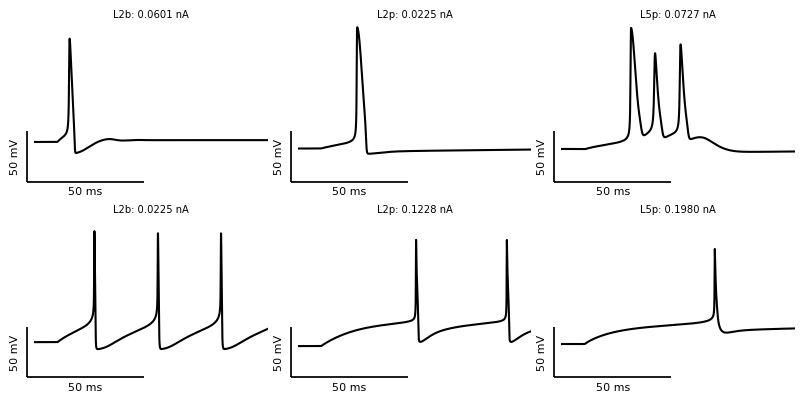

In [4]:
fig, ax = plt.subplots(2, 3, figsize=(8, 4), sharex=True, sharey=True)

cell_labels = ['L2b', 'L2p', 'L5b', 'L5p']
for i in range(3):
    c = i + 1 if i == 2 else i
    ax[0, i].plot(neynet.cell_response.times, neynet.cell_response.vsec[0][c]['soma'], color='k')
    ax[1, i].plot(neynet.cell_response.times, duenet.cell_response.vsec[0][c]['soma'], color='k')
    ax[0, i].set_title(f'{cell_labels[c]}: {rheo_neymotin[c]:.4f} nA')
    ax[1, i].set_title(f'{cell_labels[c]}: {rheo_ca[c]:.4f} nA')
    ax[0, i].set_ylim(-100, 50)
    ax[0, i].set_xlim(0, 100)
    ax[0, i].set_xticks([0, 50, 100])

    add_scalebar(ax[0, i], x_len=50, y_len=50, x_label='50 ms', y_label='50 mV')
    add_scalebar(ax[1, i], x_len=50, y_len=50, x_label='50 ms', y_label='50 mV')

fig.tight_layout()
h('forall delete_section()')

fig.savefig(figpth / 'rheo_neymotin_duecker.png')
fig.savefig(figpth / 'rheo_neymotin_duecker.pdf')
fig.savefig(figpth / 'rheo_neymotin_duecker.svg')
plt.show()

## Supp. Fig. 3c — neymotin single-cell dipoles

Single-cell dipolar currents for the `neymotin_2020_model` L2/3 and L5 pyramidal
cells (isolated cell via `mesh_shape=(1, 1)`), for comparison with the
`duecker_ET_model` versions in the single-cell notebooks. `dpl_ylim=None`
autoscales the dipole panel to each cell.

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
No baseline correction applied.
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
No baseline correction applied.
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
No baseline correction applied.
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model

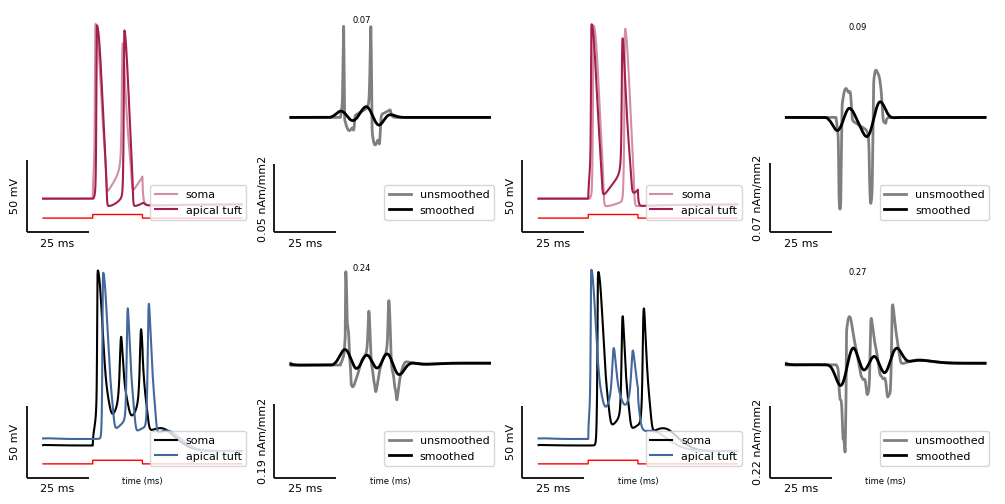

In [5]:
fig, axs = plt.subplots(2, 4, figsize=(10, 5), sharex=True)

gid = 1  # neymotin L2 pyramidal
net, dpl, smooth_dpl = stim_dpl(neymotin_2020_model(mesh_shape=(1, 1)), stim_cell='L2_pyramidal', ampl=2)
plot_dpl(net, dpl, smooth_dpl, axs[0, :2], gid, cell_type='L2_pyramidal', dpl_ylim=None)

net, dpl, smooth_dpl = stim_dpl(neymotin_2020_model(mesh_shape=(1, 1)), stim_cell='L2_pyramidal', stim_section='apical_tuft', ampl=0.6)
plot_dpl(net, dpl, smooth_dpl, axs[0, 2:], gid, cell_type='L2_pyramidal', dpl_ylim=None)

gid = 3  # neymotin L5 pyramidal
net, dpl, smooth_dpl = stim_dpl(neymotin_2020_model(mesh_shape=(1, 1)), stim_cell='L5_pyramidal', ampl=3)
plot_dpl(net, dpl, smooth_dpl, axs[1, :2], gid, cell_type='L5_pyramidal', dpl_ylim=None)

net, dpl, smooth_dpl = stim_dpl(neymotin_2020_model(mesh_shape=(1, 1)), stim_cell='L5_pyramidal', stim_section='apical_tuft', ampl=1)
plot_dpl(net, dpl, smooth_dpl, axs[1, 2:], gid, cell_type='L5_pyramidal', dpl_ylim=None)

for ax in axs[1, :]:
    ax.set_xlabel('time (ms)')

fig.tight_layout()
fig.savefig(figpth / 'neymotin_single_cell_dipoles.png', dpi=300, bbox_inches='tight')
fig.savefig(figpth / 'neymotin_single_cell_dipoles.pdf', dpi=300, bbox_inches='tight')
plt.show()